# NVIDIA Fellowship — Causal ML: real CPU/CUDA benchmark

**One-run notebook · fully synthetic · no GitHub authentication · no protected patient records**

**Hardware:** Colab → **Runtime → Change runtime type → T4 GPU** (L4 also works; A100 is unnecessary). Choose **standard RAM** and Python 3. No TPU: the code uses PyTorch **CUDA**.

**Run:** `Runtime → Run all`. A valid GPU is required, otherwise the notebook stops before benchmarking (instead of inventing timings). At the end, a ZIP containing JSON, CSV, plots, machine specs and exact experiment source is downloaded automatically. **Upload the ZIP to the existing private GitHub repo**; the research assistant will inspect results and update the paper and proposal.

**Research question:** synthetic *individualized risk from waiting* for five simulated treatment-start times. This does **not** estimate the causal effects of antibiotics on real people. The original public MIMIC-IV-ED Demo is not required for this GPU-only test.

**Evidence protocol:** same generated cohorts, seeds, model configuration and experiment settings for both CPU and CUDA; GPU synchronization for timing; a separately checked, identical-weight CPU/GPU inference test; report both total training/evaluation and scaled inference. A GPU may be slower for the small neural model; negative results remain part of the evidence.

In [1]:
from pathlib import Path
import sys, subprocess, json, os, platform, hashlib, time, datetime
import numpy as np, torch
import psutil, matplotlib, matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path('/content/nvidia_causal_benchmark') if Path('/content').exists() else Path.cwd() / 'nvidia_causal_benchmark'
SRC = ROOT/'src'; SCRIPTS = ROOT/'scripts'; OUT = ROOT/'results'
for p in (SRC, SCRIPTS, OUT):p.mkdir(parents=True, exist_ok=True)
print('PyTorch:',torch.__version__, '| CUDA build:',torch.version.cuda)
print('CUDA available:',torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('No CUDA GPU detected. In Colab choose Runtime → Change runtime type → T4 GPU, Save, Connect; then Run all again.')
print('Assigned NVIDIA GPU:',torch.cuda.get_device_name(0))
print('VRAM GiB:',round(torch.cuda.get_device_properties(0).total_memory/1024**3,2))
print('System RAM GiB:',round(psutil.virtual_memory().total/1024**3,2))

PyTorch: 2.11.0+cu130 | CUDA build: 13.0
CUDA available: True
Assigned NVIDIA GPU: Tesla T4
VRAM GiB: 14.56
System RAM GiB: 12.67


## 1. Executable source, embedded for a private-repo-safe run

These are included in full so the notebook does **not** need to clone a private repository or request your GitHub password/token. They are a Colab execution harness based on the existing dissertation's synthetic risk-curve code. The returned ZIP saves both files and their hashes, so the exact implementation can be independently inspected. The GitHub repository's older CPU model results remain separate and should not be conflated with this run.

In [2]:
%%writefile /content/nvidia_causal_benchmark/src/antibiotic_timing_synthetic.py
"""Factual-only learning of simulated individualized antibiotic initiation risk curves.

This is a controlled synthetic causal identification exercise, not a clinical or
antibiotic-safety result. Simulation ground truth is never used for model training.
With known observed time-varying propensity, unstabilized IPW addresses selection
into fixed initiation policies under simulated sequential exchangeability.
"""
from __future__ import annotations
import argparse
import json
import time
from pathlib import Path
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

HORIZON = 4  # interventions: first dose at 0,1,2,3, or no dose through time 3 (4)


def _sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -24, 24)))


def risk_process(x, severity_noise, start_time):
    """Known true event probability under fixed-dose time, given exogenous disturbances.

    x is (n,2), severity_noise (n,4), start_time (n,), where 4 means none.
    Risk is a *simulated adverse-event proxy*, NOT an actual clinical endpoint.
    """
    n = len(x)
    severity = 0.8*x[:, 0] + 0.2*x[:, 1]
    high = np.maximum(severity, 0)
    cum_untreated = np.zeros(n)
    for t in range(HORIZON):
        exposed = start_time <= t
        severity = (0.73*severity + 0.35*x[:, 0] + 0.20*x[:, 1]
                    + 0.19*(~exposed) - 0.42*exposed + 0.58*severity_noise[:, t])
        high = np.maximum(high, severity)
        cum_untreated += (~exposed)
    # Nonlinear heterogeneity means high baseline severity increases harms from deferral.
    log_odds = (-2.15 + 0.68*severity + 0.31*x[:, 0] + 0.21*x[:, 1]
                + 0.17*high + 0.115*cum_untreated
                + 0.060*cum_untreated*np.maximum(x[:, 0], 0))
    return _sigmoid(log_odds)


def simulate_factual(n, seed):
    rng = np.random.default_rng(seed)
    x = rng.normal(size=(n, 2))
    noises = rng.normal(size=(n, HORIZON))
    outcome_noise = rng.random(n)
    severity = 0.8*x[:, 0] + 0.2*x[:, 1]
    first_t = np.full(n, HORIZON, dtype=np.int64)
    prob_observed_path = np.ones(n)
    for t in range(HORIZON):
        untreated = first_t == HORIZON
        if not untreated.any():
            break
        idx = np.where(untreated)[0]
        severity[idx] = (0.73*severity[idx] + 0.35*x[idx, 0]
                         + 0.20*x[idx, 1] + 0.19 + 0.58*noises[idx, t])
        p = 0.23 + 0.37*_sigmoid(0.72*severity[idx]+0.20*x[idx, 0]+0.12*t)
        take = rng.random(len(idx)) < p
        prob_observed_path[idx] *= np.where(take, p, 1-p)
        first_t[idx[take]] = t
    factual_risk = risk_process(x, noises, first_t)
    y = (outcome_noise < factual_risk).astype(np.float32)
    return dict(x=x.astype(np.float32),
                k=first_t, y=y,
                propensity=prob_observed_path.astype(np.float32),
                noise=noises.astype(np.float32))


def oracle_personalized_risk(x, seed, draws=64):
    """MC oracle E[Y^k | baseline X=x] under a known *synthetic* DGP.

    Ground truth used for scoring ONLY. It never enters optimization.
    """
    rng = np.random.default_rng(seed)
    oracle = np.zeros((len(x), HORIZON+1))
    for _ in range(draws):
        noise = rng.normal(size=(len(x), HORIZON))
        for k in range(HORIZON+1):
            oracle[:, k] += risk_process(x, noise, np.full(len(x), k)) / draws
    return oracle


class CurveNet(nn.Module):
    def __init__(self, width=48):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(2+HORIZON+1,width),nn.SiLU(),
                               nn.Linear(width,width//2),nn.SiLU(),
                               nn.Linear(width//2,1))
    def forward(self, x, k):
        return torch.sigmoid(self.net(torch.cat([x, F.one_hot(k,HORIZON+1).float()],1)).flatten())


def _tensor(a, device, dtype=torch.float32):
    return torch.as_tensor(a, device=device, dtype=dtype)


def train_curve_model(train, validation, device="cpu", seed=41, epochs=70,
                      ipw=True, width=48, batch_size=384):
    if device == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA device unavailable: GPU benchmark not performed")
    dev=torch.device(device)
    torch.manual_seed(seed); np.random.seed(seed)
    if device=="cpu": torch.set_num_threads(2)
    model=CurveNet(width).to(dev)
    optimizer=torch.optim.AdamW(model.parameters(),lr=0.003,weight_decay=0.0004)
    xt=_tensor(train['x'],dev); yt=_tensor(train['y'],dev); kt=_tensor(train['k'],dev,torch.long)
    xv=_tensor(validation['x'],dev); yv=_tensor(validation['y'],dev)
    kv=_tensor(validation['k'],dev,torch.long)
    if ipw:
        raw=1/np.clip(train['propensity'],0.02,1.0)
        weights=np.minimum(raw,35)
        # Equal treatment-time normalization balances support across regimes.
        for k in range(HORIZON+1):
            rows=train['k']==k
            weights[rows]=weights[rows]/np.maximum(weights[rows].mean(),1e-6)
    else: weights=np.ones(len(xt))
    wt=_tensor(weights,dev)
    best=float('inf');best_state=None;bad=0;best_epoch=0
    start=time.perf_counter()
    for epoch in range(epochs):
        model.train()
        for indices in torch.randperm(len(xt),device=dev).split(batch_size):
            p=model(xt[indices],kt[indices]).clamp(1e-5,1-1e-5)
            loss=(F.binary_cross_entropy(p,yt[indices],reduction='none')*wt[indices]).mean()
            optimizer.zero_grad();loss.backward();optimizer.step()
        model.eval()
        with torch.no_grad():
            pv=model(xv,kv).clamp(1e-5,1-1e-5)
            val=float(F.binary_cross_entropy(pv,yv).item())
        if val < best-1e-4:
            best=val;bad=0;best_epoch=epoch+1
            best_state={name:w.detach().clone() for name,w in model.state_dict().items()}
        else:bad+=1
        if bad>=15:break
    model.load_state_dict(best_state)
    if dev.type=='cuda':torch.cuda.synchronize()
    elapsed=time.perf_counter()-start
    model.eval()
    return model,dict(training_seconds=round(elapsed,3),selected_epoch=best_epoch,
                      validation_log_loss=round(best,6),device=device,
                      ipw=ipw,n_training_rows=len(xt))


def score_curves(model,x,device="cpu", batch=1024):
    dev=torch.device(device)
    results=np.zeros((len(x),HORIZON+1),dtype=np.float64)
    with torch.no_grad():
        for i in range(0,len(x),batch):
            xx=_tensor(x[i:i+batch],dev)
            for k in range(HORIZON+1):
                results[i:i+len(xx),k]=model(xx,torch.full((len(xx),),k,dtype=torch.long,device=dev)).cpu().numpy()
    return results


def _metrics(est,ref):
    return dict(curve_rmse=float(np.sqrt(np.mean((est-ref)**2))),
                harm_from_waiting_rmse=float(np.sqrt(np.mean(((est[:,1:]-est[:,:1])-(ref[:,1:]-ref[:,:1]))**2))),
                mean_absolute_curve_error=float(np.mean(np.abs(est-ref))),
                urgency_at_3pct_agreement=float(np.mean(
                  ((est[:,1:]-est[:,:1])>=0.03).argmax(axis=1)==
                  ((ref[:,1:]-ref[:,:1])>=0.03).argmax(axis=1))))


def evaluate_once(seed=41,n=3200,epochs=70,device="cpu",oracle_draws=64):
    full=simulate_factual(n,seed)
    perm=np.random.default_rng(seed+600).permutation(n)
    ntrain=int(n*.70);nval=int(n*.15)
    train_ix=perm[:ntrain];val_ix=perm[ntrain:ntrain+nval];test_ix=perm[ntrain+nval:]
    subset=lambda ix:{key:v[ix] for key,v in full.items()}
    train=subset(train_ix);val=subset(val_ix);test=subset(test_ix)
    truth=oracle_personalized_risk(test['x'],seed+10000,draws=oracle_draws)
    learned={};meta={}
    for name,ipw in [('factual_unweighted',False),('factual_ipw',True)]:
        model,info=train_curve_model(train,val,device,seed,epochs,ipw=ipw)
        estimates=score_curves(model,test['x'],device)
        learned[name]=estimates;meta[name]=info
    naive=np.tile(np.asarray([train['y'][train['k']==k].mean() for k in range(HORIZON+1)]),(len(test_ix),1))
    result={
        'seed':seed,'n_people':n,'n_test_people':len(test_ix),
        'n_train':len(train_ix),'n_validation':len(val_ix),
        'observed_dose_time_counts':np.bincount(full['k'],minlength=HORIZON+1).tolist(),
        'interventions':'simulated first-dose t=0,1,2,3 or none through horizon',
        'oracle_population_risk_by_start_time':np.round(truth.mean(axis=0),6).tolist(),
        'unadjusted_group_risk_by_observed_treatment_time':np.round(naive.mean(axis=0),6).tolist(),
        'ipw_learned_population_risk':np.round(learned['factual_ipw'].mean(axis=0),6).tolist(),
        'mean_true_harm_of_delay_time3_vs_time0':float((truth[:,3]-truth[:,0]).mean()),
        'metrics':{**{key:_metrics(est,truth) for key,est in learned.items()},'naive_group_means':_metrics(naive,truth)},
        'training':meta,
        'sample_curve_x':np.round(test['x'][:3],3).tolist(),
        'sample_curve_truth':np.round(truth[:3],5).tolist(),
        'sample_curve_ipw':np.round(learned['factual_ipw'][:3],5).tolist(),
        'device':device,'source':'Independent synthetic DGP / factual-only learned estimator',
        'limitations':[
          'No real EHR patients or antibiotic administration are modeled',
          'Reported risk is a simulated event probability, not sepsis mortality',
          'Oracle conditional risk is available only because this is a simulation',
          'IPW uses known true treatment propensities from the synthetic generator',
          'This is not individualized clinical effect identification, and no safe delay is claimed',
          'GPU speedup requires matched independent CUDA experiment']
    }
    return result


def summarize(runs):
    keys=['factual_ipw','factual_unweighted','naive_group_means']
    return {key:{metric:round(float(np.mean([r['metrics'][key][metric] for r in runs])),6)
                  for metric in ['curve_rmse','harm_from_waiting_rmse','mean_absolute_curve_error']}
            for key in keys}


def main():
    p=argparse.ArgumentParser()
    p.add_argument('--seeds',default='41,42,43')
    p.add_argument('--patients',type=int,default=3200)
    p.add_argument('--epochs',type=int,default=70)
    p.add_argument('--oracle-draws',type=int,default=64)
    p.add_argument('--device',choices=['cpu','cuda'],default='cpu')
    p.add_argument('--out',type=Path,default=Path('results/personalized_timing_synthetic.json'))
    a=p.parse_args()
    if a.device=='cuda' and not torch.cuda.is_available():
        raise SystemExit('CUDA device unavailable: GPU benchmark NOT performed')
    runs=[evaluate_once(int(s),a.patients,a.epochs,a.device,a.oracle_draws)
          for s in a.seeds.split(',')]
    data=dict(experiment='Synthetic individualized first-dose-time risk curves',runs=runs,
              average_metrics=summarize(runs),gpu_speedup_measured=False,
              clinical_treatment_effect_estimated=False)
    a.out.parent.mkdir(parents=True,exist_ok=True)
    a.out.write_text(json.dumps(data,indent=2)+'\n',encoding='utf-8')
    print(json.dumps({'average_metrics':data['average_metrics'],
                      'risk_oracle':runs[0]['oracle_population_risk_by_start_time'],
                      'risk_ipw':runs[0]['ipw_learned_population_risk'],
                      'training':runs[0]['training']},indent=2))

if __name__=='__main__':main()

Writing /content/nvidia_causal_benchmark/src/antibiotic_timing_synthetic.py


In [3]:
%%writefile /content/nvidia_causal_benchmark/scripts/benchmark_cpu_cuda.py
"""Matched synthetic-risk-curve CPU/CUDA benchmarking.

Runs only devices actually present, never estimates GPU speedup from model names.
Same dataset, seeds, model parameters and training protocol per device. Supports
CPU as a valid result and records a NOT_RUN status for absent CUDA GPUs.
"""
import argparse, json, os, platform, sys, time
from pathlib import Path
import psutil
import torch
sys.path.insert(0,str(Path(__file__).resolve().parents[1]/'src'))
from antibiotic_timing_synthetic import evaluate_once


def execute(device, seeds, patients, epochs, oracle_draws):
    outputs=[]
    if device=='cuda' and not torch.cuda.is_available():
        return {'status':'NOT_RUN_NO_CUDA_DEVICE','device':'cuda','runs':[],
                'explanation':'No NVIDIA CUDA GPU exposed to this runtime; no GPU timings or speedup measured.'}
    for seed in seeds:
        if device=='cuda':torch.cuda.reset_peak_memory_stats();torch.cuda.synchronize()
        start=time.perf_counter()
        run=evaluate_once(seed,patients,epochs,device,oracle_draws)
        if device=='cuda':torch.cuda.synchronize()
        elapsed=time.perf_counter()-start
        outputs.append({'seed':seed,'end_to_end_seconds':round(elapsed,5),
                        'ipw_curve_rmse':run['metrics']['factual_ipw']['curve_rmse'],
                        'unweighted_curve_rmse':run['metrics']['factual_unweighted']['curve_rmse'],
                        'max_cuda_memory_bytes':int(torch.cuda.max_memory_allocated()) if device=='cuda' else None,
                        'rss_bytes_at_end':int(psutil.Process().memory_info().rss)})
    return {'status':'COMPLETED','device':device,'runs':outputs,
            'median_end_to_end_seconds':round(sorted(x['end_to_end_seconds'] for x in outputs)[len(outputs)//2],5)}


def main():
    p=argparse.ArgumentParser()
    p.add_argument('--devices',default='cpu,cuda')
    p.add_argument('--seeds',default='41,42,43')
    p.add_argument('--patients',type=int,default=3200)
    p.add_argument('--epochs',type=int,default=70)
    p.add_argument('--oracle-draws',type=int,default=64)
    p.add_argument('--output',type=Path,default=Path('results/compute-benchmark.json'))
    a=p.parse_args()
    devices=[s.strip() for s in a.devices.split(',') if s.strip()]
    seeds=[int(s) for s in a.seeds.split(',')]
    runs={device:execute(device,seeds,a.patients,a.epochs,a.oracle_draws) for device in devices}
    cpu=runs.get('cpu',{})
    cuda=runs.get('cuda',{})
    speedup=(cpu['median_end_to_end_seconds']/cuda['median_end_to_end_seconds']
             if cpu.get('status')=='COMPLETED' and cuda.get('status')=='COMPLETED' else None)
    data={'experiment':'End-to-end matched synthetic risk-curve execution benchmark',
          'inputs':{'seeds':seeds,'patients':a.patients,'epochs':a.epochs,'oracle_draws':a.oracle_draws},
          'runtime':{'python':platform.python_version(),'torch':torch.__version__,
                     'torch_cuda_compiled':torch.version.cuda,
                     'cuda_available':torch.cuda.is_available(),
                     'cuda_device_name':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
                     'platform':platform.platform()},
          'devices':runs,'measured_cuda_speedup':round(speedup,4) if speedup is not None else None,
          'important_scope':'Only synthetic model training and curve evaluation; not clinical causal effect.'}
    a.output.parent.mkdir(parents=True,exist_ok=True)
    a.output.write_text(json.dumps(data,indent=2)+'\n',encoding='utf8')
    print(json.dumps({'devices':{k:{'status':v['status'],'median':v.get('median_end_to_end_seconds')} for k,v in runs.items()},
                      'speedup':speedup},indent=2))

if __name__=='__main__':main()

Writing /content/nvidia_causal_benchmark/scripts/benchmark_cpu_cuda.py


## 2. Test known counterfactual truth and run **both** hardware backends

A code checksum, structured training logs and hardware details are saved. This uses **three independent seeds**, **3,200 simulated subjects each**, five timing strategies, a baseline model and a weighted neural model. The small experiment may favor CPU because GPU-launch overhead can dominate.

In [4]:
import sys, csv
sys.path.insert(0,str(SRC))
from antibiotic_timing_synthetic import simulate_factual, oracle_personalized_risk, evaluate_once, train_curve_model, score_curves
x=simulate_factual(48,123)
assert len(x['x'])==48 and x['k'].min()>=0 and x['k'].max()<=4
tru=oracle_personalized_risk(x['x'],321,draws=12)
assert tru.shape==(48,5) and np.isfinite(tru).all()
print('Synthetic oracle and factual-data shape checks passed.')

# Can lower epochs to 50 only if the available Colab session is restricted;
# changes are logged, and CPU/GPU use the same values.
SEEDS = [41,42,43]
N_PATIENTS=3200
EPOCHS=70
ORACLE_DRAWS=64
command=[sys.executable, str(SCRIPTS/'benchmark_cpu_cuda.py'),
         '--devices','cpu,cuda','--seeds',','.join(map(str,SEEDS)),
         '--patients',str(N_PATIENTS),'--epochs',str(EPOCHS),
         '--oracle-draws',str(ORACLE_DRAWS),'--output',str(OUT/'training_compute_benchmark.json')]
started=time.perf_counter()
subprocess.run(command,check=True,timeout=1200)
print('Matched training/evaluation completed in',round(time.perf_counter()-started,2),'s')
bench=json.loads((OUT/'training_compute_benchmark.json').read_text())
assert bench['devices']['cpu']['status']=='COMPLETED'
assert bench['devices']['cuda']['status']=='COMPLETED', 'CUDA failed; no speedup may be claimed.'
assert bench['measured_cuda_speedup'] is not None

Synthetic oracle and factual-data shape checks passed.
Matched training/evaluation completed in 17.29 s


## 3. Scientific validity: identical weights, matched input, measured inference

For numerical parity, the **same fitted model state** is evaluated on both CPU and CUDA. This is a separate check from training, where device-specific floating-point/random operations can produce small differences. The larger inference run measures whether batched counterfactual scans can profit from the GPU; it must not be represented as an observed clinical outcome.

In [5]:
import statistics
import torch.nn.functional as F
from antibiotic_timing_synthetic import CurveNet

# Fit one model using synthetic factual outcomes only; use EXACTLY its same
# weights on CPU and GPU for controlled inference comparisons.
d=simulate_factual(5000,777)
rng=np.random.default_rng(877)
ids=rng.permutation(len(d['x']))
select=lambda idx:{name:value[idx] for name,value in d.items()}
tr=select(ids[:3500]);val=select(ids[3500:4250]);
trained, train_info=train_curve_model(tr,val,'cpu',seed=777,epochs=70,ipw=True)
trained.eval()
gpu_model=CurveNet().to('cuda')
gpu_model.load_state_dict(trained.state_dict())
gpu_model.eval()

# A fixed synthetic input, never drawn from real patients.
MAX_N = 160000
inputs=np.random.default_rng(20261021).normal(size=(MAX_N,2)).astype(np.float32)

def matched_scan(model, x, device, batch=8192):
    output=np.zeros((len(x),5), dtype=np.float32)
    with torch.inference_mode():
        for pos in range(0,len(x),batch):
            xb=torch.as_tensor(x[pos:pos+batch],device=device)
            expanded=xb.repeat_interleave(5, dim=0)
            k=torch.arange(5,device=device).repeat(len(xb))
            scores=model(expanded,k).reshape(-1,5)
            output[pos:pos+len(xb)]=scores.cpu().numpy()
    if device=='cuda':torch.cuda.synchronize()
    return output

protocols=[]
for size in [3200,160000]:
    xx=inputs[:size]
    # Warm up CPU and GPU, excluded from measured rounds.
    for _ in range(2):
        matched_scan(trained,xx,'cpu')
        matched_scan(gpu_model,xx,'cuda')
    torch.cuda.reset_peak_memory_stats()
    timings={};baseline={}
    for device,model in [('cpu',trained),('cuda',gpu_model)]:
        trial=[]
        for rep in range(3):
            if device=='cuda':torch.cuda.synchronize()
            t0=time.perf_counter()
            pred=matched_scan(model,xx,device)
            if device=='cuda':torch.cuda.synchronize()
            trial.append(time.perf_counter()-t0)
            if rep==0:baseline[device]=pred
        timings[device]=[round(x,6) for x in trial]
    errors=np.abs(baseline['cpu']-baseline['cuda'])
    max_error=float(errors.max());mae=float(errors.mean())
    parity=max_error<=1e-4
    row={'n_individuals':size,'n_scenarios':5,'candidate_predictions':size*5,
         'cpu_repeats_sec':timings['cpu'],'cuda_repeats_sec':timings['cuda'],
         'cpu_median_sec':round(statistics.median(timings['cpu']),6),
         'cuda_median_sec':round(statistics.median(timings['cuda']),6),
         'gpu_vs_cpu_speedup':round(statistics.median(timings['cpu'])/statistics.median(timings['cuda']),4),
         'max_absolute_cpu_cuda_prediction_error':max_error,
         'mean_absolute_cpu_cuda_prediction_error':mae,
         'numeric_parity_at_tolerance_1e-4':parity,
         'cuda_peak_allocated_bytes':int(torch.cuda.max_memory_allocated())}
    protocols.append(row)
    print('Input',size,'| CPU',row['cpu_median_sec'],'s | GPU',row['cuda_median_sec'],
          's | speedup',row['gpu_vs_cpu_speedup'],'x | max abs error',round(max_error,9))

(OUT/'inference_compute_benchmark.json').write_text(json.dumps({'protocol':'identical-weights CPU/CUDA timing scans, copy-to-device and copy-back included; model transfer excluded; warmup excluded',
                                      'model_fit':'synthetic factual-only PyTorch neural model',
                                      'rows':protocols},indent=2))
if not all(r['numeric_parity_at_tolerance_1e-4'] for r in protocols):
    print('WARNING: prediction parity exceeded 1e-4; do not quote speedup as fidelity-preserving.')

Input 3200 | CPU 0.02682 s | GPU 0.001259 s | speedup 21.3026 x | max abs error 1.19e-07
Input 160000 | CPU 0.237679 s | GPU 0.020659 s | speedup 11.5049 x | max abs error 1.19e-07


## 4. Produce reviewer-ready aggregate charts, hardware record and files

Artifacts are saved locally in Colab, then exported as one ZIP. They contain synthetic findings only; no private GitHub token, personal medical records, or Google credentials are required.

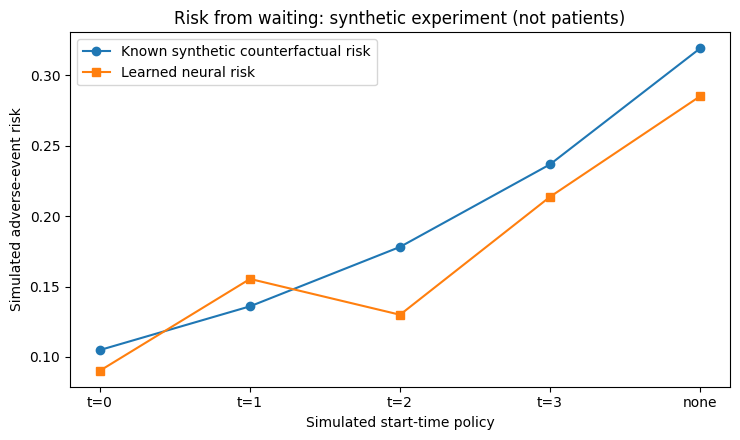

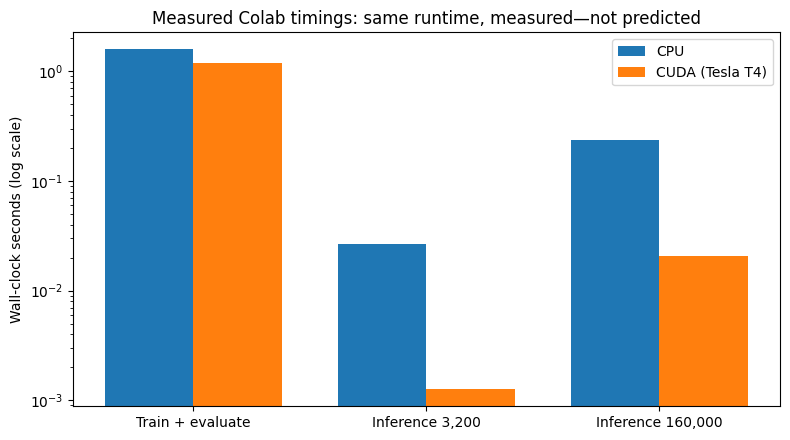

RESULTS PACKAGE READY: /content/nvidia_causal_benchmark/NVIDIA_Colab_CPU_CUDA_Results_20261021_072400_UTC.zip
Upload the downloaded ZIP into the existing private GitHub repository, or send it back into this chat.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import matplotlib.pyplot as plt
from hashlib import sha256
import subprocess, zipfile, shutil

hardware={
  'recorded_at_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
  'python':platform.python_version(),
  'platform':platform.platform(),
  'cpu_model':next((x.split(':',1)[1].strip() for x in Path('/proc/cpuinfo').read_text().splitlines() if x.startswith('model name')),None) if Path('/proc/cpuinfo').exists() else platform.processor(),
  'logical_cpu_count':os.cpu_count(),
  'system_ram_gib':round(psutil.virtual_memory().total/2**30,3),
  'pytorch_version':torch.__version__,
  'compiled_cuda_version':torch.version.cuda,
  'torch_cuda_available':torch.cuda.is_available(),
  'assigned_gpu_name':torch.cuda.get_device_name(0),
  'gpu_vram_gib':round(torch.cuda.get_device_properties(0).total_memory/2**30,3),
  'source_hashes_sha256':{
      'src/antibiotic_timing_synthetic.py':sha256((SRC/'antibiotic_timing_synthetic.py').read_bytes()).hexdigest(),
      'scripts/benchmark_cpu_cuda.py':sha256((SCRIPTS/'benchmark_cpu_cuda.py').read_bytes()).hexdigest()
  },
  'environment':'Google Colab' if 'google.colab' in sys.modules else 'Jupyter',
}
try:
    cmd=subprocess.run(['nvidia-smi','--query-gpu=driver_version,memory.total','--format=csv,noheader'],capture_output=True,text=True,timeout=10)
    hardware['nvidia_driver_and_memory']=cmd.stdout.strip() if cmd.returncode==0 else 'unavailable'
except Exception:
    hardware['nvidia_driver_and_memory']='unavailable'
(OUT/'hardware.json').write_text(json.dumps(hardware,indent=2))

# Verified clinical scope and aggregate curve chart (simulation truth only)
with torch.no_grad():
    clinical_scope={'clinical_EHR_used':False,'measured_antibiotic_effect_in_patients':False,
                    'synthetic_oracle_accessible_only_in_simulation':True,
                    'runtime_type':'actual NVIDIA CUDA GPU',
                    'training_speedup':bench['measured_cuda_speedup'],
                    'inference_speedups':[{k:v for k,v in row.items() if k in ['n_individuals','gpu_vs_cpu_speedup','numeric_parity_at_tolerance_1e-4']} for row in protocols]}
(OUT/'scope_and_summary.json').write_text(json.dumps(clinical_scope,indent=2))

rs=evaluate_once(seed=41,n=1800,epochs=50,device='cuda',oracle_draws=32)
times=['t=0','t=1','t=2','t=3','none']
fig,ax=plt.subplots(figsize=(7.5,4.5))
ax.plot(times,rs['oracle_population_risk_by_start_time'],marker='o',label='Known synthetic counterfactual risk')
ax.plot(times,rs['ipw_learned_population_risk'],marker='s',label='Learned neural risk')
ax.set(xlabel='Simulated start-time policy',ylabel='Simulated adverse-event risk',title='Risk from waiting: synthetic experiment (not patients)')
ax.legend();fig.tight_layout();fig.savefig(OUT/'synthetic_risk_curves.png',dpi=180);plt.show();plt.close(fig)

labels=['Train + evaluate']+[f"Inference {z['n_individuals']:,}" for z in protocols]
cpu=[bench['devices']['cpu']['median_end_to_end_seconds']]+[z['cpu_median_sec'] for z in protocols]
gpu=[bench['devices']['cuda']['median_end_to_end_seconds']]+[z['cuda_median_sec'] for z in protocols]
fig,ax=plt.subplots(figsize=(8,4.5))
loc=np.arange(len(labels));w=.38
ax.bar(loc-w/2,cpu,width=w,label='CPU')
ax.bar(loc+w/2,gpu,width=w,label=f"CUDA ({hardware['assigned_gpu_name']})")
ax.set_xticks(loc,labels);ax.set_yscale('log');ax.set_ylabel('Wall-clock seconds (log scale)')
ax.set_title('Measured Colab timings: same runtime, measured—not predicted')
ax.legend();fig.tight_layout();fig.savefig(OUT/'cpu_cuda_measured_times.png',dpi=180);plt.show();plt.close(fig)

with (OUT/'summary.csv').open('w',newline='') as f:
    writer=csv.writer(f)
    writer.writerow(['workload','cpu_median_seconds','cuda_median_seconds','gpu_speedup_x','max_abs_numeric_error'])
    writer.writerow(['full_train_evaluate',cpu[0],gpu[0],bench['measured_cuda_speedup'],'N/A - retrained'])
    for r in protocols:writer.writerow([f"inference_{r['n_individuals']}",r['cpu_median_sec'],r['cuda_median_sec'],r['gpu_vs_cpu_speedup'],r['max_absolute_cpu_cuda_prediction_error']])

report=f"""# Google Colab GPU benchmark — measured run

- GPU: **{hardware['assigned_gpu_name']}**, VRAM **{hardware['gpu_vram_gib']} GiB**; system RAM **{hardware['system_ram_gib']} GiB**.
- Training/evaluation workload: **{N_PATIENTS} synthetic subjects × {len(SEEDS)} seeds** with {EPOCHS} epochs max; CPU median **{cpu[0]:.4f} sec**, CUDA median **{gpu[0]:.4f} sec**, GPU/CPU speed ratio **{bench['measured_cuda_speedup']:.3f}×**.
- Identical-weight inference runs: {', '.join(f"{r['n_individuals']:,} subjects -> {r['gpu_vs_cpu_speedup']:.3f}×, numerical max error {r['max_absolute_cpu_cuda_prediction_error']:.2e}" for r in protocols)}.
- Counterfactual outcome curves were evaluated against **known simulated truth**, not clinical EHR outcomes.
- CUDA timings and system properties come from the actual run; the model can be slower on GPU for small batches.
- GPU device memory and CPU system RAM are distinct; benchmark performance is conditional on Colab allocation.
- **Clinical claim:** NONE. This does not estimate antibiotic harm in real patients or prove clinical effectiveness.

See `training_compute_benchmark.json`, `inference_compute_benchmark.json`, `hardware.json`, `scope_and_summary.json` and plots for full details.
"""
(OUT/'RUN_REPORT.md').write_text(report)

export_root=ROOT/'export_bundle'
if export_root.exists():shutil.rmtree(export_root)
(export_root/'results').mkdir(parents=True)
(export_root/'source').mkdir(parents=True)
for fn in OUT.iterdir():
    if fn.is_file():shutil.copy2(fn,export_root/'results'/fn.name)
shutil.copy2(SRC/'antibiotic_timing_synthetic.py',export_root/'source/antibiotic_timing_synthetic.py')
shutil.copy2(SCRIPTS/'benchmark_cpu_cuda.py',export_root/'source/benchmark_cpu_cuda.py')

stamp=datetime.datetime.now(datetime.timezone.utc).strftime('%Y%m%d_%H%M%S_UTC')
archive=ROOT/f'NVIDIA_Colab_CPU_CUDA_Results_{stamp}.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for file in export_root.rglob('*'):
        if file.is_file():z.write(file,arcname=file.relative_to(export_root))
print('RESULTS PACKAGE READY:',archive)
print('Upload the downloaded ZIP into the existing private GitHub repository, or send it back into this chat.')
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    print('Manual artifact path:',archive)